In [75]:
import pandas as pd 
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline 
import plotly.graph_objs as go
import plotly.figure_factory as ff
from plotly import tools
from plotly.offline import download_plotlyjs, init_notebook_mode, plot, iplot
init_notebook_mode(connected=True)


import gc
from datetime import datetime 
from sklearn.model_selection import train_test_split
from sklearn.model_selection import KFold
from sklearn.metrics import roc_auc_score
from sklearn.ensemble import RandomForestClassifier
from sklearn.ensemble import AdaBoostClassifier
from catboost import CatBoostClassifier
from sklearn import svm
import lightgbm as lgb
from lightgbm import LGBMClassifier
import xgboost as xgb

RFC_METRIC = 'gini'  #metric used for RandomForestClassifier
NUM_ESTIMATORS = 100 #number of estimators used for RandomForestClassifier
NO_JOBS = 4 #number of parallel jobs used for RandomForestClassifier


#TRAIN/VALIDATION/TEST SPLIT
#VALIDATION
VALID_SIZE = 0.20 # simple validation using train_test_split
TEST_SIZE = 0.20 # test size using_train_test_split

#CROSS-VALIDATION
NUMBER_KFOLDS = 5 #number of KFolds for cross-validation



RANDOM_STATE = 2018

MAX_ROUNDS = 1000 #lgb iterations
EARLY_STOP = 50 #lgb early stop 
OPT_ROUNDS = 1000  #To be adjusted based on best validation rounds
VERBOSE_EVAL = 50 #Print out metric result

# Read Data

In [76]:
data_df = pd.read_csv('creditcard.csv')
data_df.head()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


# Check the Data

## Glimpse the Data

In [77]:
print("Credit Card Fraud Detection data -  rows:",data_df.shape[0]," columns:", data_df.shape[1])

Credit Card Fraud Detection data -  rows: 284807  columns: 31


In [78]:
data_df.describe()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
count,284807.000000,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,...,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,284807.000000,284807.000000
mean,94813.859575,1.175161e-15,3.384974e-16,-1.379537e-15,2.094852e-15,1.021879e-15,1.494498e-15,-5.620335e-16,1.149614e-16,-2.414189e-15,...,1.628620e-16,-3.576577e-16,2.618565e-16,4.473914e-15,5.109395e-16,1.686100e-15,-3.661401e-16,-1.227452e-16,88.349619,0.001727
std,47488.145955,1.958696e+00,1.651309e+00,1.516255e+00,1.415869e+00,1.380247e+00,1.332271e+00,1.237094e+00,1.194353e+00,1.098632e+00,...,7.345240e-01,7.257016e-01,6.244603e-01,6.056471e-01,5.212781e-01,4.822270e-01,4.036325e-01,3.300833e-01,250.120109,0.041527
min,0.000000,-5.640751e+01,-7.271573e+01,-4.832559e+01,-5.683171e+00,-1.137433e+02,-2.616051e+01,-4.355724e+01,-7.321672e+01,-1.343407e+01,...,-3.483038e+01,-1.093314e+01,-4.480774e+01,-2.836627e+00,-1.029540e+01,-2.604551e+00,-2.256568e+01,-1.543008e+01,0.000000,0.000000
25%,54201.500000,-9.203734e-01,-5.985499e-01,-8.903648e-01,-8.486401e-01,-6.915971e-01,-7.682956e-01,-5.540759e-01,-2.086297e-01,-6.430976e-01,...,-2.283949e-01,-5.423504e-01,-1.618463e-01,-3.545861e-01,-3.171451e-01,-3.269839e-01,-7.083953e-02,-5.295979e-02,5.600000,0.000000
50%,84692.000000,1.810880e-02,6.548556e-02,1.798463e-01,-1.984653e-02,-5.433583e-02,-2.741871e-01,4.010308e-02,2.235804e-02,-5.142873e-02,...,-2.945017e-02,6.781943e-03,-1.119293e-02,4.097606e-02,1.659350e-02,-5.213911e-02,1.342146e-03,1.124383e-02,22.000000,0.000000
75%,139320.500000,1.315642e+00,8.037239e-01,1.027196e+00,7.433413e-01,6.119264e-01,3.985649e-01,5.704361e-01,3.273459e-01,5.971390e-01,...,1.863772e-01,5.285536e-01,1.476421e-01,4.395266e-01,3.507156e-01,2.409522e-01,9.104512e-02,7.827995e-02,77.165000,0.000000
max,172792.000000,2.454930e+00,2.205773e+01,9.382558e+00,1.687534e+01,3.480167e+01,7.330163e+01,1.205895e+02,2.000721e+01,1.559499e+01,...,2.720284e+01,1.050309e+01,2.252841e+01,4.584549e+00,7.519589e+00,3.517346e+00,3.161220e+01,3.384781e+01,25691.160000,1.000000


## check missing values

In [79]:
# missing values
data_df.isnull().sum()

Time      0
V1        0
V2        0
V3        0
V4        0
V5        0
V6        0
V7        0
V8        0
V9        0
V10       0
V11       0
V12       0
V13       0
V14       0
V15       0
V16       0
V17       0
V18       0
V19       0
V20       0
V21       0
V22       0
V23       0
V24       0
V25       0
V26       0
V27       0
V28       0
Amount    0
Class     0
dtype: int64

## Data Unbalance

In [80]:
temp = data_df["Class"].value_counts()
df = pd.DataFrame({'class': temp.index, 'values': temp.values})

trace = go.Bar(
    x = df['class'], y = df['values'],
    name = "Credit card Fraud Class - Data unbalance (Not found = 0, Found = 1)",
    marker = dict(color = df['values'], colorscale='Viridis'),
)

data = [trace]
layout = dict(title = 'Credit Card Fraud Class - data unbalance (Not fraud = 0, Fraud = 1)',
          xaxis = dict(title = 'Class', showticklabels=True), 
          yaxis = dict(title = 'Number of transactions'),
          hovermode = 'closest',width=600
         )
fig = dict(data=data, layout=layout)
iplot(fig, filename='class')

Only *492* (or 0.172%) of transaction are fraudulent. That means the data is highly unbalanced with respect with target variable Class.

# Exploration Data Analysis

## Transaction in time

In [81]:
import plotly.graph_objects as go
from scipy.stats import gaussian_kde

class_0 = data_df[data_df['Class'] == 0]['Time']
class_1 = data_df[data_df['Class'] == 1]['Time']

fig = go.Figure()
for time_values, label, color in [
    (class_0, 'Not Fraud', '#636EFA'),
    (class_1, 'Fraud', '#EF553B'),
]:
    x = np.linspace(time_values.min(), time_values.max(), 500)
    y = gaussian_kde(time_values)(x)
    fig.add_trace(go.Scatter(x=x, y=y, mode='lines', name=label,
                             line=dict(color=color, width=2)))

fig.update_layout(
    title='Credit Card Transactions Time Density Plot',
    xaxis_title='Time [s]',
    yaxis_title='Density',
    hovermode='x unified',
)
fig.show()


Fraudulent transactions have a distribution more even than valid transactions - are equaly distributed in time, including the low real transaction times, during night in Europe timezone.

Let's look into more details to the time distribution of both classes transaction, as well as to aggregated values of transaction count and amount, per hour. We assume (based on observation of the time distribution of transactions) that the time unit is second.

In [82]:
data_df['Hour'] = data_df['Time'].apply(lambda x: np.floor(x / 3600))

tmp = data_df.groupby(['Hour', 'Class',])['Amount'].aggregate(['min', 'max', 'count', 'sum', 'mean', 'median', 'var']).reset_index()

df = pd.DataFrame(tmp)
df.columns = ['Hour', 'Class', 'Min', 'Max', 'Transactions', 'Sum', 'Mean', 'Median', 'Var']
df.head()

,Hour,Class,Min,Max,Transactions,Sum,Mean,Median,Var
0,0.0,0,0.0,7712.43,3961,256572.87,64.774772,12.990,45615.821201
1,0.0,1,0.0,529.00,2,529.00,264.500000,264.500,139920.500000
2,1.0,0,0.0,1769.69,2215,145806.76,65.826980,22.820,20053.615770
3,1.0,1,59.0,239.93,2,298.93,149.465000,149.465,16367.832450
4,2.0,0,0.0,4002.88,1555,106989.39,68.803466,17.900,45355.430437


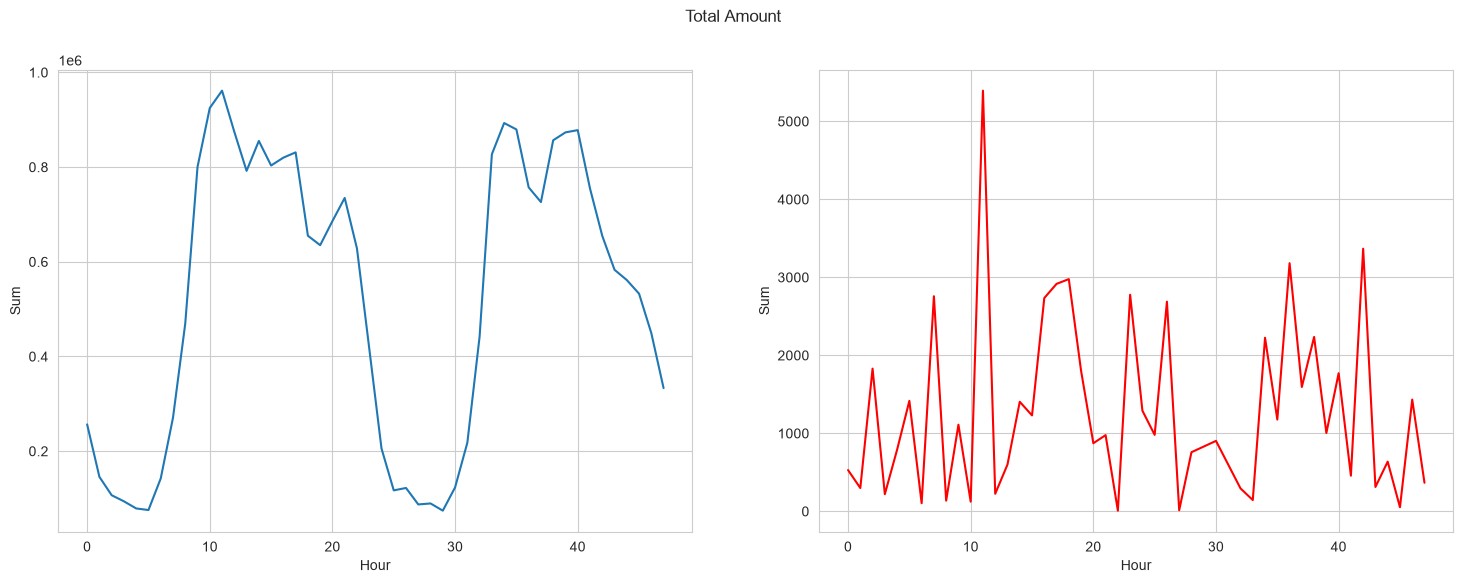

In [83]:
fig, (ax1, ax2) = plt.subplots(ncols=2, figsize=(18,6))
s = sns.lineplot(ax = ax1, x="Hour", y="Sum", data=df.loc[df.Class==0])
s = sns.lineplot(ax = ax2, x="Hour", y="Sum", data=df.loc[df.Class==1], color="red")
plt.suptitle("Total Amount")
plt.show()

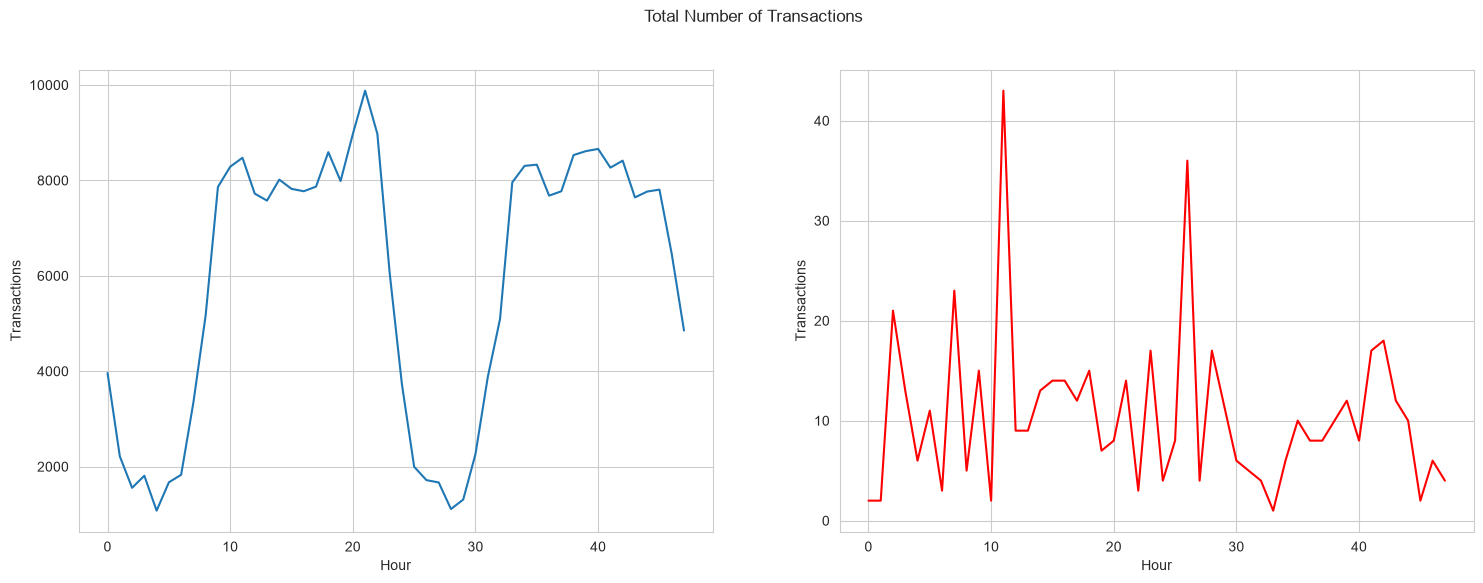

In [84]:
fig, (ax1, ax2) = plt.subplots(ncols=2, figsize=(18,6))
s = sns.lineplot(ax = ax1, x="Hour", y="Transactions", data=df.loc[df.Class==0])
s = sns.lineplot(ax = ax2, x="Hour", y="Transactions", data=df.loc[df.Class==1], color="red")
plt.suptitle("Total Number of Transactions")
plt.show()

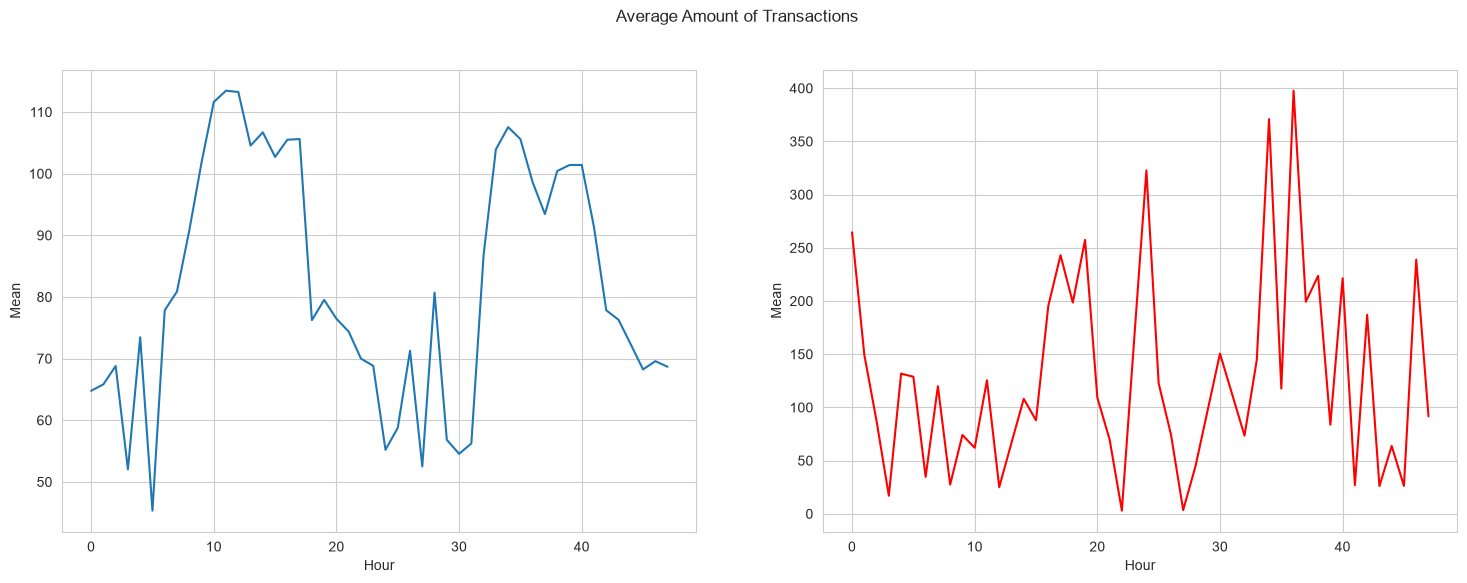

In [85]:
fig, (ax1, ax2) = plt.subplots(ncols=2, figsize = (18, 6))
s = sns.lineplot(ax = ax1, x="Hour", y = "Mean", data=df.loc[df.Class==0])
s = sns.lineplot(ax = ax2, x="Hour", y="Mean", data=df.loc[df.Class==1], color="red")
plt.suptitle("Average Amount of Transactions")
plt.show()

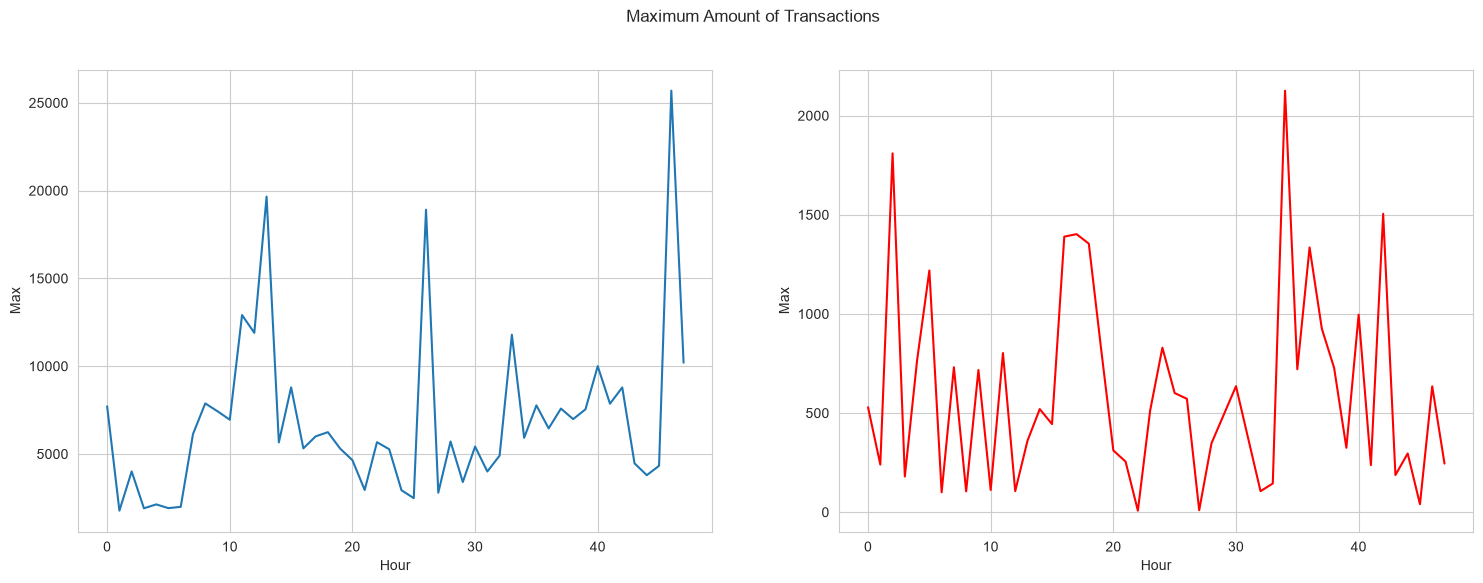

In [86]:
fig, (ax1, ax2) = plt.subplots(ncols=2, figsize=(18,6))
s = sns.lineplot(ax = ax1, x="Hour", y="Max", data=df.loc[df.Class==0])
s = sns.lineplot(ax = ax2, x="Hour", y="Max", data=df.loc[df.Class==1], color="red")
plt.suptitle("Maximum Amount of Transactions")
plt.show()

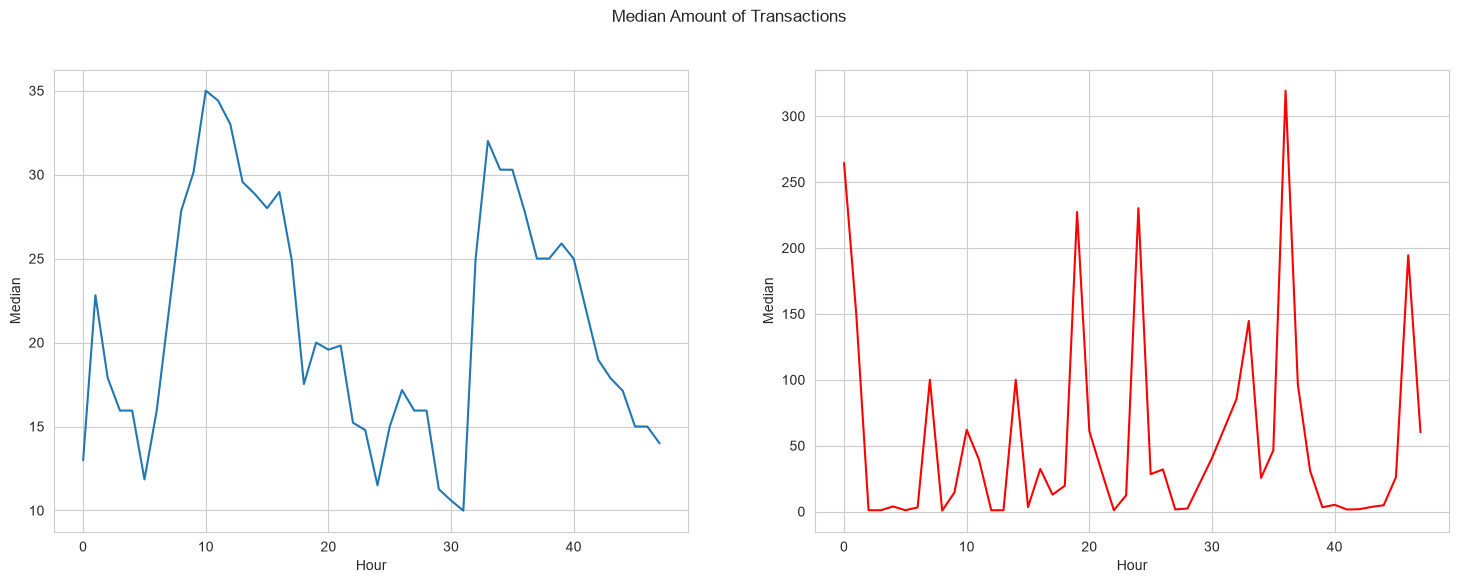

In [87]:
fig, (ax1, ax2) = plt.subplots(ncols=2, figsize=(18,6))
s = sns.lineplot(ax = ax1, x="Hour", y="Median", data=df.loc[df.Class==0])
s = sns.lineplot(ax = ax2, x="Hour", y="Median", data=df.loc[df.Class==1], color="red")
plt.suptitle("Median Amount of Transactions")
plt.show()

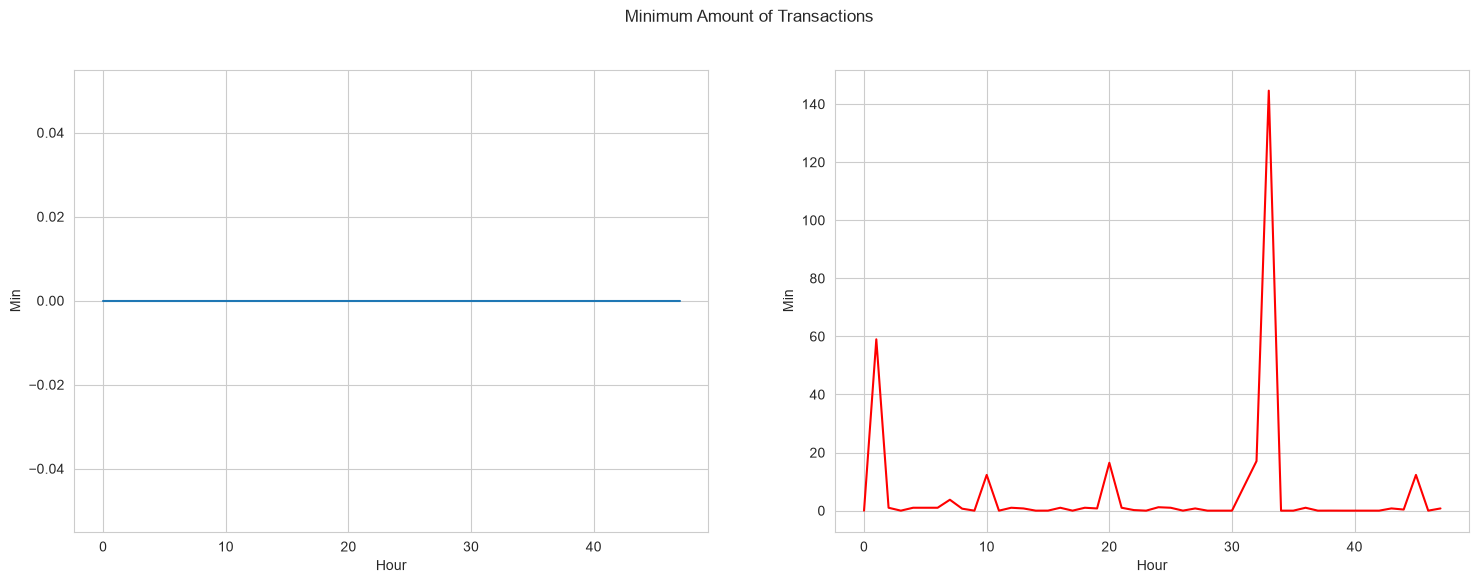

In [88]:
fig, (ax1, ax2) = plt.subplots(ncols=2, figsize=(18,6))
s = sns.lineplot(ax = ax1, x="Hour", y="Min", data=df.loc[df.Class==0])
s = sns.lineplot(ax = ax2, x="Hour", y="Min", data=df.loc[df.Class==1], color="red")
plt.suptitle("Minimum Amount of Transactions")
plt.show()

## Transactions amount

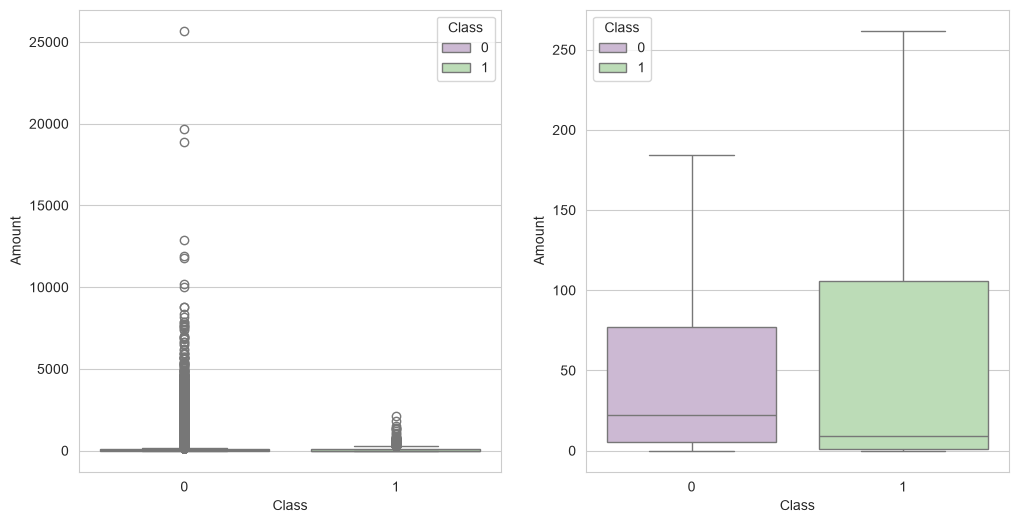

In [89]:
fig, (ax1, ax2) = plt.subplots(ncols =2, figsize=(12,6))
s = sns.boxplot(ax = ax1, x="Class", y="Amount", hue="Class", data=data_df, palette="PRGn", showfliers= True)
s = sns.boxplot(ax = ax2, x="Class", y="Amount", hue="Class",data=data_df, palette="PRGn",showfliers=False)
plt.show()

In [90]:
tmp = data_df[['Amount','Class']].copy()
class_0 = tmp.loc[tmp['Class'] == 0]['Amount']
class_1 = tmp.loc[tmp['Class'] == 1]['Amount']
class_0.describe()


count    284315.000000
mean         88.291022
std         250.105092
min           0.000000
25%           5.650000
50%          22.000000
75%          77.050000
max       25691.160000
Name: Amount, dtype: float64

In [91]:
class_1.describe()

count     492.000000
mean      122.211321
std       256.683288
min         0.000000
25%         1.000000
50%         9.250000
75%       105.890000
max      2125.870000
Name: Amount, dtype: float64

The real transaction have a larger mean value, larger Q1, smaller Q3 and Q4 and larger outliers; fraudulent transactions have a smaller Q1 and mean, larger Q4 and smaller outliers.

Let's plot the fraudulent transactions (amount) against time. The time is shown is seconds from the start of the time period (totaly 48h, over 2 days).

In [92]:
fraud = data_df.loc[data_df['Class'] == 1]

trace = go.Scatter(
    x = fraud['Time'],y = fraud['Amount'],
    name="Amount",
     marker=dict(
                color='rgb(238,23,11)',
                line=dict(
                    color='red',
                    width=1),
                opacity=0.5,
            ),
    text= fraud['Amount'],
    mode = "markers"
)
data = [trace]
layout = dict(title = 'Amount of fraudulent transactions',
          xaxis = dict(title = 'Time [s]', showticklabels=True), 
          yaxis = dict(title = 'Amount'),
          hovermode='closest'
         )
fig = dict(data=data, layout=layout)
iplot(fig, filename='fraud-amount')

## Features correlation

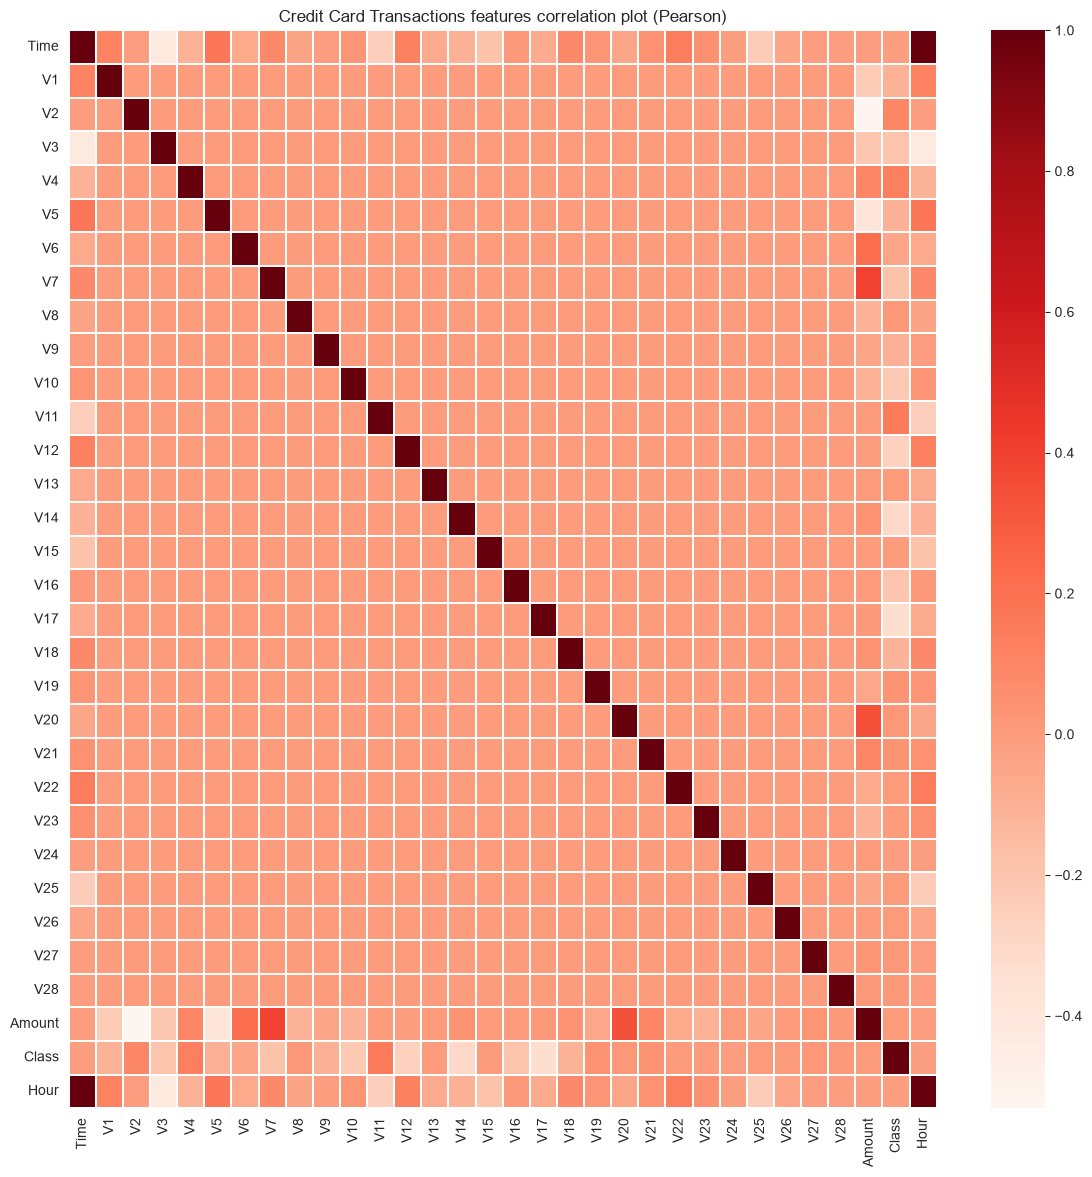

In [93]:
plt.figure(figsize = (14,14))
plt.title('Credit Card Transactions features correlation plot (Pearson)')
corr = data_df.corr()
sns.heatmap(corr,xticklabels=corr.columns,yticklabels=corr.columns,linewidths=.1,cmap="Reds")
plt.show()

As expected, there is no notable correlation between features V1-V28. There are certain correlations between some of these features and Time (inverse correlation with V3) and Amount (direct correlation with V7 and V20, inverse correlation with V1 and V5).

Let's plot the correlated and inverse correlated values on the same graph.

Let's start with the direct correlated values: {V20;Amount} and {V7;Amount}.

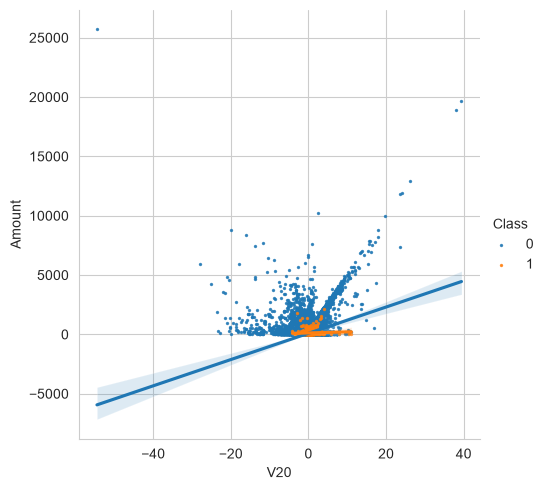

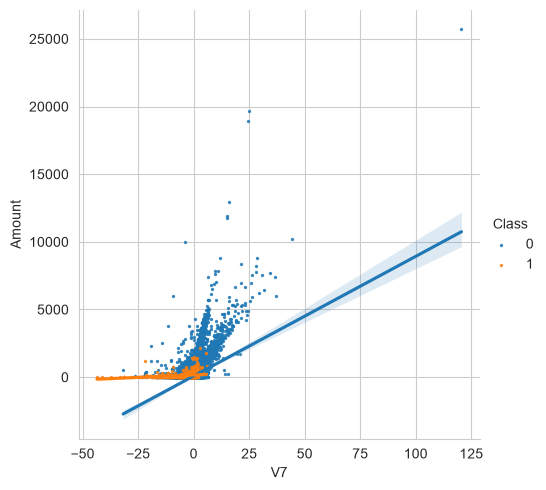

In [94]:
s = sns.lmplot(x='V20', y='Amount',data=data_df, hue='Class', fit_reg=True,scatter_kws={'s':2})
s = sns.lmplot(x='V7', y='Amount',data=data_df, hue='Class', fit_reg=True,scatter_kws={'s':2})
plt.show()

We can confirm that the two couples of features are correlated (the regression lines for Class = 0 have a positive slope, whilst the regression line for Class = 1 have a smaller positive slope).

Let's plot now the inverse correlated values.

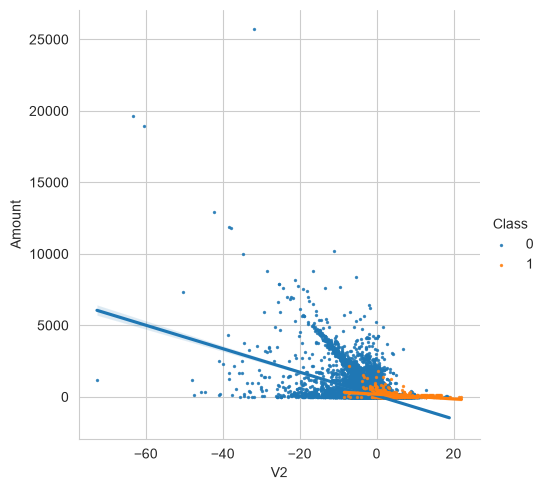

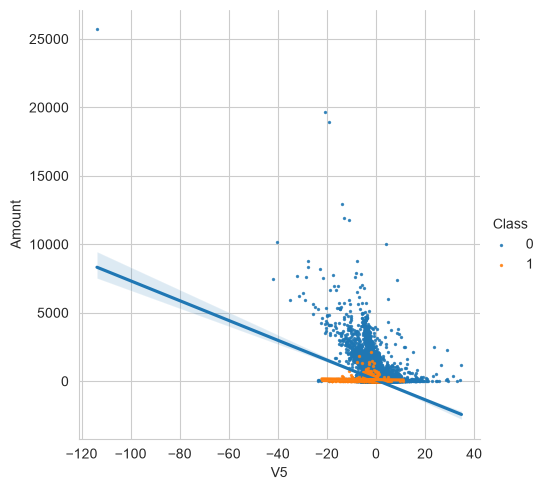

In [95]:
s = sns.lmplot(x='V2', y='Amount',data=data_df, hue='Class', fit_reg=True,scatter_kws={'s':2})
s = sns.lmplot(x='V5', y='Amount',data=data_df, hue='Class', fit_reg=True,scatter_kws={'s':2})
plt.show()

We can confirm that the two couples of features are inverse correlated (the regression lines for Class = 0 have a negative slope while the regression lines for Class = 1 have a very small negative slope).

## Features density plot

C:\Users\Asus\AppData\Local\Temp\ipykernel_18764\2022268144.py:14: UserWarning: 

The `bw` parameter is deprecated in favor of `bw_method` and `bw_adjust`.
Setting `bw_method=0.5`, but please see the docs for the new parameters
and update your code. This will become an error in seaborn v0.14.0.

  sns.kdeplot(t0[feature], bw=0.5,label="Class = 0")
C:\Users\Asus\AppData\Local\Temp\ipykernel_18764\2022268144.py:15: UserWarning: 

The `bw` parameter is deprecated in favor of `bw_method` and `bw_adjust`.
Setting `bw_method=0.5`, but please see the docs for the new parameters
and update your code. This will become an error in seaborn v0.14.0.

  sns.kdeplot(t1[feature], bw=0.5,label="Class = 1")
C:\Users\Asus\AppData\Local\Temp\ipykernel_18764\2022268144.py:14: UserWarning: 

The `bw` parameter is deprecated in favor of `bw_method` and `bw_adjust`.
Setting `bw_method=0.5`, but please see the docs for the new parameters
and update your code. This will become an error in seaborn v0.14.0.

  s

<Figure size 640x480 with 0 Axes>

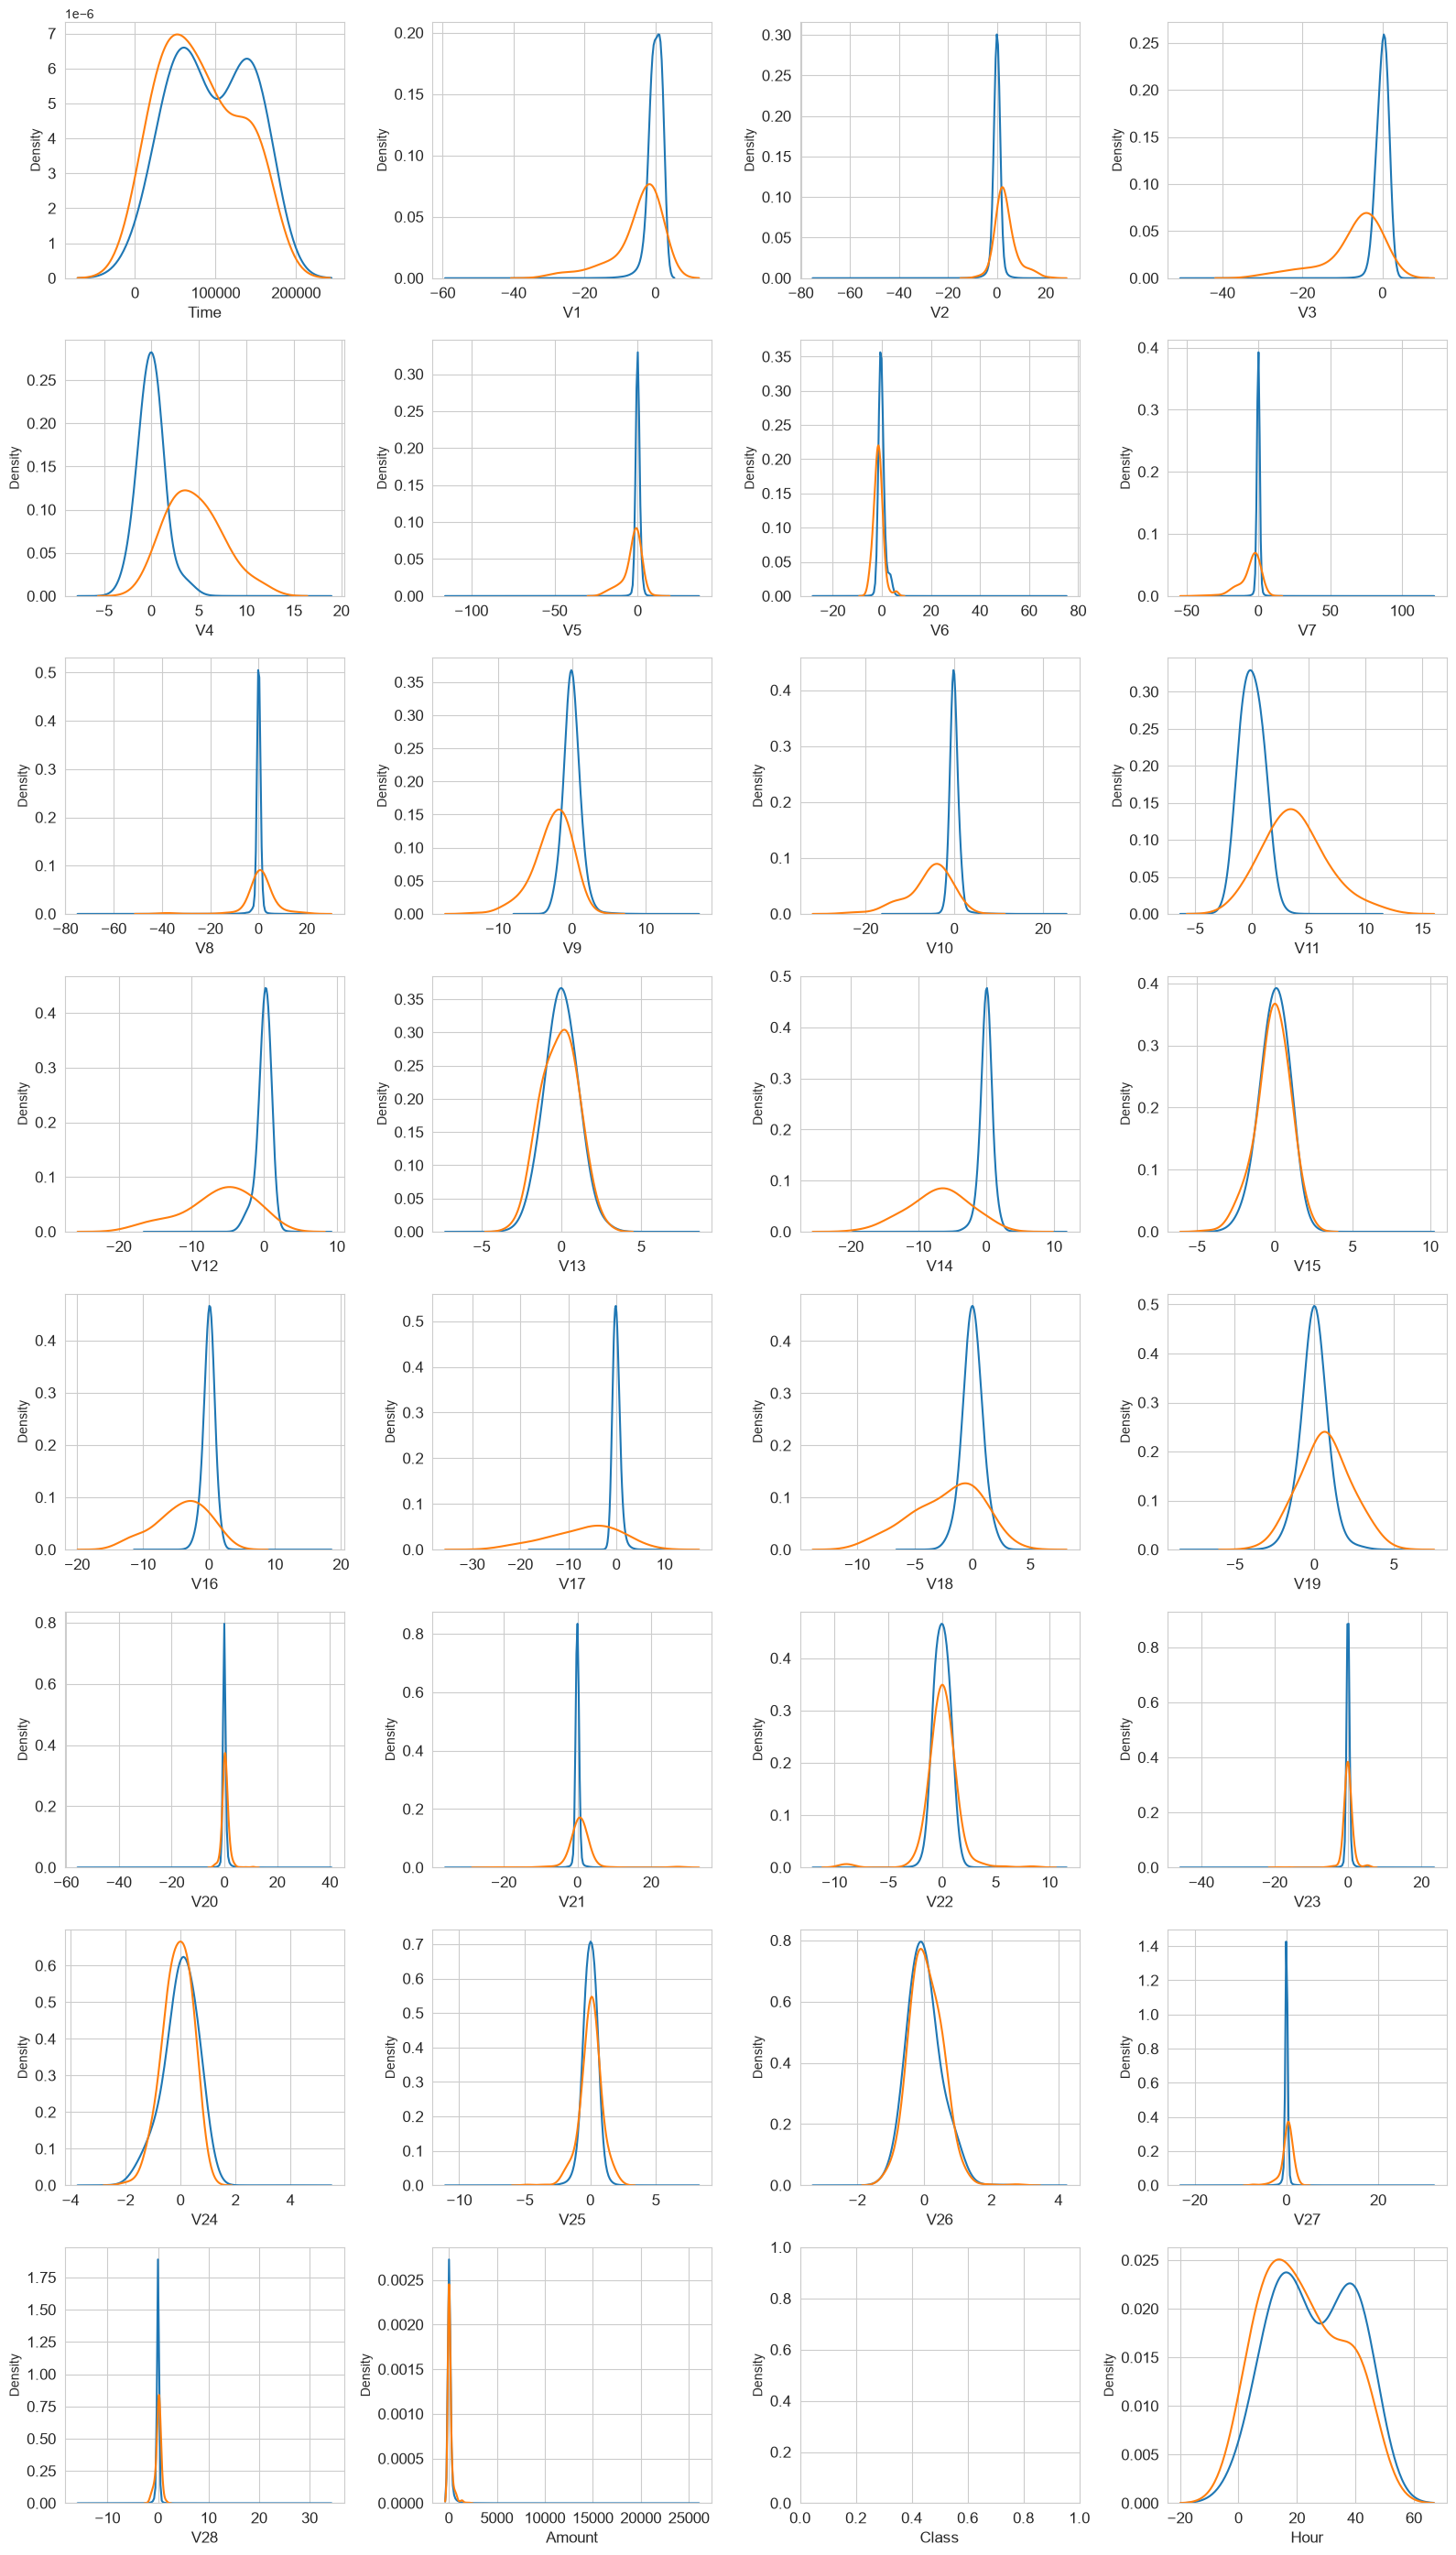

In [96]:
var = data_df.columns.values

i = 0
t0 = data_df.loc[data_df['Class'] == 0]
t1 = data_df.loc[data_df['Class'] == 1]

sns.set_style('whitegrid')
plt.figure()
fig, ax = plt.subplots(8,4,figsize=(16,28))

for feature in var:
    i += 1
    plt.subplot(8,4,i)
    sns.kdeplot(t0[feature], bw=0.5,label="Class = 0")
    sns.kdeplot(t1[feature], bw=0.5,label="Class = 1")
    plt.xlabel(feature, fontsize=12)
    locs, labels = plt.xticks()
    plt.tick_params(axis='both', which='major', labelsize=12)
plt.tight_layout()
plt.show()

Untuk beberapa fitur, kita dapat mengamati selektivitas yang baik dalam hal distribusi untuk kedua nilai Kelas: V4 dan V11 memiliki distribusi yang jelas terpisah untuk nilai Kelas 0 dan 1; V12, V14, dan V18 terpisah sebagian; V1, V2, V3, dan V10 memiliki profil yang cukup berbeda; sedangkan V25, V26, dan V28 memiliki profil yang serupa untuk kedua nilai Kelas tersebut.

Secara umum, dengan hanya beberapa pengecualian (Time dan Amount), distribusi fitur untuk transaksi sah (nilai Class = 0) berpusat di sekitar 0, terkadang dengan antrian panjang di salah satu ujungnya. Di saat yang sama, transaksi penipuan (nilai Class = 1) memiliki distribusi yang miring (asimetris).

# Predictive models

**Define predictors and target values**

Let's define the predictor features and the target features. Categorical features, if any, are also defined. In our case, there are no categorical feature.

In [97]:
target = 'Class'
predictors = ['Time', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10',\
       'V11', 'V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18', 'V19',\
       'V20', 'V21', 'V22', 'V23', 'V24', 'V25', 'V26', 'V27', 'V28',\
       'Amount']

**Split data in train, test and validation set**

Let's define train, validation and test sets.

In [98]:
train_df, test_df = train_test_split(data_df, test_size=TEST_SIZE, random_state=RANDOM_STATE, shuffle=True )
train_df, valid_df = train_test_split(train_df, test_size=VALID_SIZE, random_state=RANDOM_STATE, shuffle=True )

## RandomForestClassifier

**Define model parameters**
Let's set the parameters for the model.

Let's run a model using the training set for training. Then, we will use the validation set for validation.

We will use as validation criterion GINI, which formula is GINI = 2 * (AUC) - 1, where AUC is the Receiver Operating Characteristic - Area Under Curve (ROC-AUC) [4]. Number of estimators is set to 100 and number of parallel jobs is set to 4.

In [99]:
clf = RandomForestClassifier(n_jobs=NO_JOBS, 
                             random_state=RANDOM_STATE,
                             criterion=RFC_METRIC,
                             n_estimators=NUM_ESTIMATORS,
                             verbose=False)

Let's train the **RandomForestClassifier** using the **train_df** data and **fit** function.

In [100]:
clf.fit(train_df[predictors], train_df[target].values)

,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",4
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",2018
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the tota

Let's now predict the **target** values for the **valid_df** data, using predict function.

In [101]:
preds = clf.predict(valid_df[predictors])

C:\Users\Asus\AppData\Local\Temp\ipykernel_18764\1035525770.py:6: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  s.set_xticklabels(s.get_xticklabels(),rotation=90)


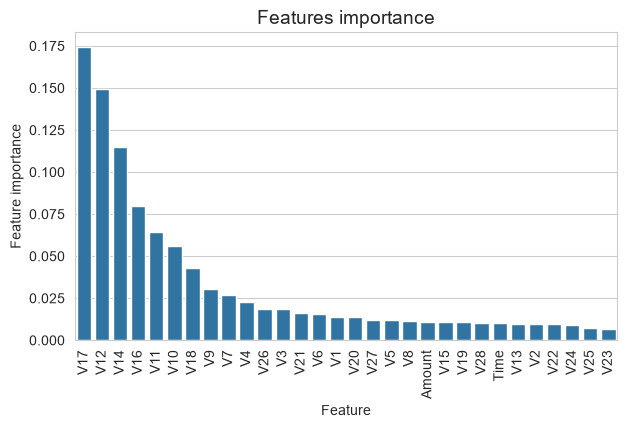

In [102]:
tmp = pd.DataFrame({'Feature': predictors, 'Feature importance': clf.feature_importances_})
tmp = tmp.sort_values(by='Feature importance',ascending=False)
plt.figure(figsize = (7,4))
plt.title('Features importance',fontsize=14)
s = sns.barplot(x='Feature',y='Feature importance',data=tmp)
s.set_xticklabels(s.get_xticklabels(),rotation=90)
plt.show() 

The most important features are **V17, V12, V14, V10, V11, V16.**

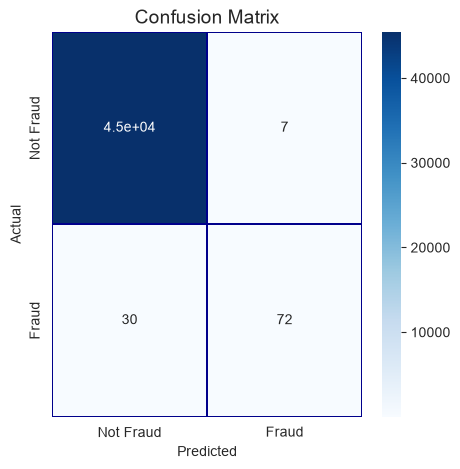

In [103]:
cm = pd.crosstab(valid_df[target].values, preds, rownames=['Actual'], colnames=['Predicted'])
fig, (ax1) = plt.subplots(ncols=1, figsize=(5,5))
sns.heatmap(cm, 
            xticklabels=['Not Fraud', 'Fraud'],
            yticklabels=['Not Fraud', 'Fraud'],
            annot=True,ax=ax1,
            linewidths=.2,linecolor="Darkblue", cmap="Blues")
plt.title('Confusion Matrix', fontsize=14)
plt.show()

Kesalahan Tipe I dan Kesalahan Tipe II
Perlu kami jelaskan bahwa matriks kebingungan bukanlah alat yang tepat untuk menggambarkan hasil pada kasus data yang sangat tidak seimbang, karena pada kenyataannya kita memerlukan metrik lain yang secara bersamaan memperhitungkan selektivitas dan spesifisitas metode yang kita gunakan, sehingga kita dapat meminimalkan kesalahan Tipe I dan kesalahan Tipe II secara bersamaan.

Hipotesis Nol (H0) - Transaksi tersebut bukan penipuan.
Hipotesis Alternatif (H1) - Transaksi tersebut merupakan penipuan.

Kesalahan Tipe I - Anda menolak hipotesis nol padahal hipotesis nol tersebut sebenarnya benar.
Kesalahan Tipe II - Anda gagal menolak hipotesis nol padahal hipotesis alternatif benar.

Biaya kesalahan Tipe I - Anda secara keliru menganggap bahwa transaksi tersebut merupakan penipuan, sehingga transaksi yang sah ditolak.
Biaya kesalahan Tipe II - Anda secara keliru menganggap bahwa transaksi tersebut bukan penipuan, sehingga transaksi penipuan diterima.

In [104]:
roc_auc_score(valid_df[target].values, preds)

0.8528641975628091

In [105]:
proba_rf = clf.predict_proba(valid_df[predictors])[:, 1]
proba_rf_test = clf.predict_proba(test_df[predictors])[:, 1]
roc_auc_score(valid_df[target].values, proba_rf)


0.9097061130740374

The ROC-AUC score obtained with **RandomForestClassifier** is **0.85** when it is
computed from the predicted class labels (`predict`).

AUC computed from class labels is misleading on data this unbalanced: it only sees
the two discrete values 0 and 1, so all ranking information is lost. Using the
predicted probabilities instead gives **0.91** on the same validation set.


## AdaBoostClassifier
AdaBoostClassifier stands for Adaptive Boosting Classifier.

**Prepare the model**
Let's set the parameters for the model and initialize the model.

In [106]:
clf = AdaBoostClassifier(random_state=RANDOM_STATE,
                         learning_rate=0.8,
                         n_estimators=NUM_ESTIMATORS)

In [107]:
# Fit the model
clf.fit(train_df[predictors], train_df[target].values)

,"n_estimators n_estimators: int, default=50The maximum number of estimators at which boosting is terminated.In case of perfect fit, the learning procedure is stopped early.Values must be in the range `[1, inf)`.",100
,"learning_rate learning_rate: float, default=1.0Weight applied to each classifier at each boosting iteration. A higherlearning rate increases the contribution of each classifier. There isa trade-off between the `learning_rate` and `n_estimators` parameters.Values must be in the range `(0.0, inf)`.",0.8
,"random_state random_state: int, RandomState instance or None, default=NoneControls the random seed given at each `estimator` at eachboosting iteration.Thus, it is only used when `estimator` exposes a `random_state`.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",2018
,"estimator estimator: object, default=NoneThe base estimator from which the boosted ensemble is built.Support for sample weighting is required, as well as proper``classes_`` and ``n_classes_`` attributes. If ``None``, thenthe base estimator is :class:`~sklearn.tree.DecisionTreeClassifier`initialized with `max_depth=1`... versionadded:: 1.2 `base_estimator` was renamed to `estimator`.",None
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels.","ndarray[int64](2,)","[0,1]"
estimator_ estimator_: estimatorThe base estimator from which the ensemble is grown... versionadded:: 1.2 `base_estimator_` was renamed to `estimator_`.,DecisionTreeClassifier,DecisionTreeC...r(max_depth=1)
estimator_errors_ estimator_errors_: ndarray of floatsClassification error for each estimator in the boostedensemble.,"ndarray[float64](100,)","[0. ,0.09,0.23,...,0.48,0.48,0.47]"
estimator_weights_ estimator_weights_: ndarray of floatsWeights for each estimator in the boosted ensemble.,"ndarray[float64](100,)","[5.73,1.83,0.98,...,0.07,0.07,0.11]"
estimators_ estimators_: list of classifiersThe collection of fitted sub-estimators.,list,"[DecisionTreeC...te=1642177786), DecisionTreeC...te=1829562982), DecisionTreeC...ate=448084194), DecisionTreeC...te=1902725897), ...]"
"feature_importances_ feature_importances_: ndarray of shape (n_features,)The impurity-based feature importances if supported by the``estimator`` (when based on decision trees).Warning: impurity-based feature importances can be misleading forhigh cardinality features (many unique values). See:func:`sklearn.inspection.permutation_importance` as an alternative.","ndarray[float64](30,)","[0.04,0. ,0.02,...,0. ,0.02,0.03]"


In [108]:
# Predict the target values
preds = clf.predict(valid_df[predictors])

C:\Users\Asus\AppData\Local\Temp\ipykernel_18764\3992975389.py:6: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  s.set_xticklabels(s.get_xticklabels(),rotation=90)


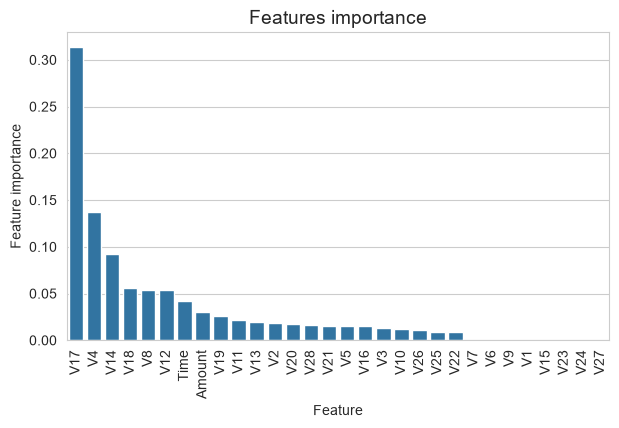

In [109]:
tmp = pd.DataFrame({'Feature': predictors, 'Feature importance': clf.feature_importances_})
tmp = tmp.sort_values(by='Feature importance',ascending=False)
plt.figure(figsize = (7,4))
plt.title('Features importance',fontsize=14)
s = sns.barplot(x='Feature',y='Feature importance',data=tmp)
s.set_xticklabels(s.get_xticklabels(),rotation=90)
plt.show()   

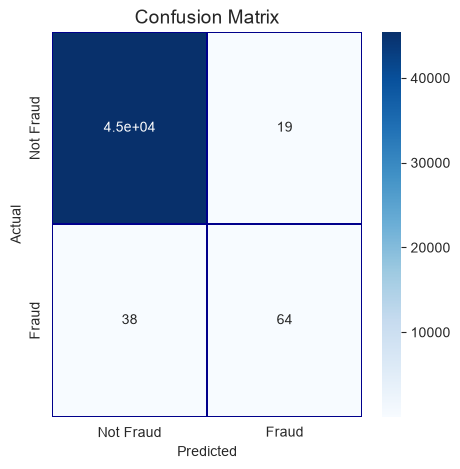

In [110]:
# Confusion matrix
cm = pd.crosstab(valid_df[target].values, preds, rownames=['Actual'], colnames=['Predicted'])
fig, (ax1) = plt.subplots(ncols=1, figsize=(5,5))
sns.heatmap(cm, 
            xticklabels=['Not Fraud', 'Fraud'],
            yticklabels=['Not Fraud', 'Fraud'],
            annot=True,ax=ax1,
            linewidths=.2,linecolor="Darkblue", cmap="Blues")
plt.title('Confusion Matrix', fontsize=14)
plt.show()

In [111]:
proba_ada = clf.predict_proba(valid_df[predictors])[:, 1]
proba_ada_test = clf.predict_proba(test_df[predictors])[:, 1]
print('AUC from predicted labels:      ', roc_auc_score(valid_df[target].values, preds))
print('AUC from predicted probabilities:', roc_auc_score(valid_df[target].values, proba_ada))


AUC from predicted labels:       0.8135165474463918
AUC from predicted probabilities: 0.9833898060950907


## CatBoostClassifier
CatBoostClassifier is a gradient boosting for decision trees algorithm with support for handling categorical data

**Prepare the model**

Let's set the parameters for the model and initialize the model.

In [112]:
clf = CatBoostClassifier(iterations=500,
                             learning_rate=0.02,
                             depth=12,
                             eval_metric='AUC',
                             random_seed = RANDOM_STATE,
                             bagging_temperature = 0.2,
                             od_type='Iter',
                             metric_period = VERBOSE_EVAL,
                             od_wait=100)

In [113]:
clf.fit(train_df[predictors], train_df[target].values,verbose=True)

0:	total: 293ms	remaining: 2m 26s
50:	total: 16.1s	remaining: 2m 21s
100:	total: 31.1s	remaining: 2m 2s
150:	total: 45.2s	remaining: 1m 44s
200:	total: 59.2s	remaining: 1m 28s
250:	total: 1m 13s	remaining: 1m 12s
300:	total: 1m 27s	remaining: 57.8s
350:	total: 1m 44s	remaining: 44.3s
400:	total: 2m 3s	remaining: 30.6s
450:	total: 2m 20s	remaining: 15.3s
499:	total: 2m 35s	remaining: 0us


CatBoostClassifier(bagging_temperature=0.2, depth=12, eval_metric='AUC', iterations=500, learning_rate=0.02, metric_period=50, od_type='Iter', od_wait=100, random_seed=2018)

In [114]:
# predict the target values
preds = clf.predict(valid_df[predictors])

C:\Users\Asus\AppData\Local\Temp\ipykernel_18764\2769129468.py:7: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  s.set_xticklabels(s.get_xticklabels(),rotation=90)


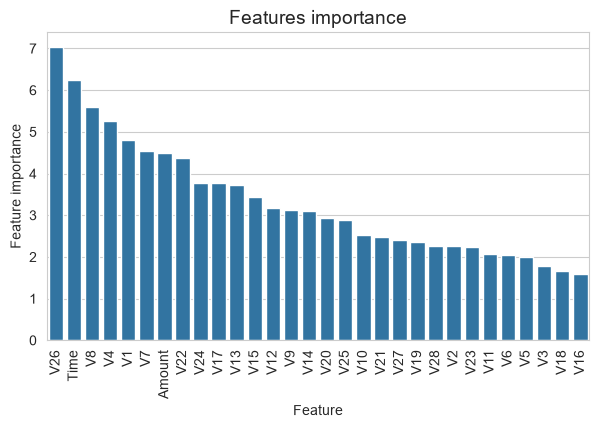

In [115]:
# feature importance
tmp = pd.DataFrame({'Feature': predictors, 'Feature importance': clf.feature_importances_})
tmp = tmp.sort_values(by='Feature importance',ascending=False)
plt.figure(figsize = (7,4))
plt.title('Features importance',fontsize=14)
s = sns.barplot(x='Feature',y='Feature importance',data=tmp)
s.set_xticklabels(s.get_xticklabels(),rotation=90)
plt.show()

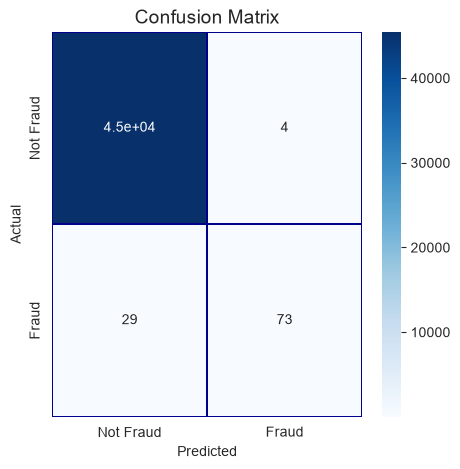

In [116]:
# Confusion matrix
cm = pd.crosstab(valid_df[target].values, preds, rownames=['Actual'], colnames=['Predicted'])
fig, (ax1) = plt.subplots(ncols=1, figsize=(5,5))
sns.heatmap(cm,
            xticklabels=['Not Fraud', 'Fraud'],
            yticklabels=['Not Fraud', 'Fraud'],
            annot=True,ax=ax1,
            linewidths=.2,linecolor="Darkblue", cmap="Blues")
plt.title('Confusion Matrix', fontsize=14)
plt.show()


In [117]:
proba_cat = clf.predict_proba(valid_df[predictors])[:, 1]
proba_cat_test = clf.predict_proba(test_df[predictors])[:, 1]
print('AUC from predicted labels:      ', roc_auc_score(valid_df[target].values, preds))
print('AUC from predicted probabilities:', roc_auc_score(valid_df[target].values, proba_cat))


AUC from predicted labels:       0.8577991493075996
AUC from predicted probabilities: 0.984340722014717


## XGBoost
XGBoost is a gradient boosting algorithm.

**Let's prepare the model.**

Prepare the model
We initialize the DMatrix objects for training and validation, starting from the datasets. We also set some of the parameters used for the model tuning.

In [118]:
# Prepare the train and valid datasets
dtrain = xgb.DMatrix(train_df[predictors], train_df[target].values)
dvalid = xgb.DMatrix(valid_df[predictors], valid_df[target].values)
dtest = xgb.DMatrix(test_df[predictors], test_df[target].values)

#What to monitor (in this case, **train** and **valid**)
watchlist = [(dtrain, 'train'), (dvalid, 'valid')]

# Set xgboost parameters
params = {}
params['objective'] = 'binary:logistic'
params['eta'] = 0.039
params['silent'] = True
params['max_depth'] = 2
params['subsample'] = 0.8
params['colsample_bytree'] = 0.9
params['eval_metric'] = 'auc'
params['random_state'] = RANDOM_STATE

In [119]:
# Train the model
model = xgb.train(params, 
                dtrain, 
                MAX_ROUNDS, 
                watchlist, 
                early_stopping_rounds=EARLY_STOP, 
                maximize=True, 
                verbose_eval=VERBOSE_EVAL)

c:\Users\Asus\anaconda3\envs\py311-ml\Lib\site-packages\xgboost\core.py:748: FutureWarning: Pass `evals` as keyword args.
  warnings.warn(msg, FutureWarning)
c:\Users\Asus\anaconda3\envs\py311-ml\Lib\site-packages\xgboost\callback.py:385: UserWarning: [15:01:53] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:782: 
Parameters: { "silent" } are not used.

  self.starting_round = model.num_boosted_rounds()


[0]	train-auc:0.93758	valid-auc:0.88823
[50]	train-auc:0.98295	valid-auc:0.97288
[100]	train-auc:0.99025	valid-auc:0.97831
[127]	train-auc:0.99245	valid-auc:0.97808


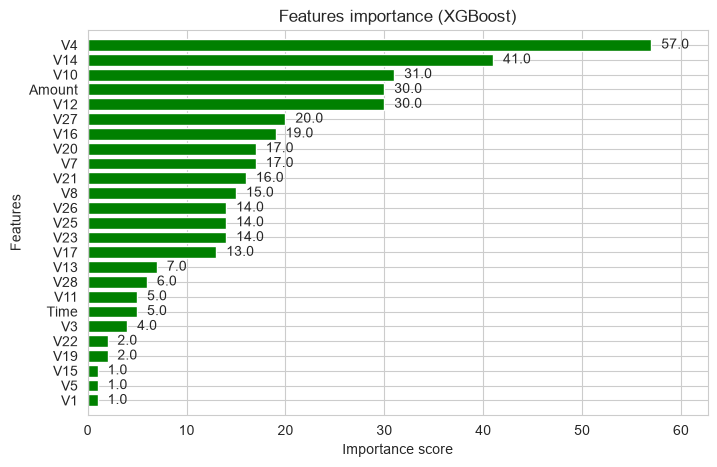

In [120]:
# plot variable importance
fig, (ax) = plt.subplots(ncols=1, figsize=(8,5))
xgb.plot_importance(model, height=0.8, title="Features importance (XGBoost)", ax=ax, color="green") 
plt.show()

**Predict test set**

We used the train and validation sets for training and validation. We will use the trained model now to predict the target value for the test set.

In [121]:
preds = model.predict(dtest)


In [122]:
proba_xgb_test = preds
proba_xgb_valid = model.predict(dvalid)
print('Best validation AUC: %.6f (iteration %d)' % (model.best_score, model.best_iteration))
print('Test AUC: %.6f' % roc_auc_score(test_df[target].values, proba_xgb_test))


Best validation AUC: 0.979582 (iteration 77)
Test AUC: 0.971909


## LightGBM
Let's continue with another gradient boosting algorithm, LightGBM.

Define model parameters
Let's set the parameters for the model. We will use these parameters only for the first lgb model.

In [123]:
params = {
          'boosting_type': 'gbdt',
          'objective': 'binary',
          'metric':'auc',
          'learning_rate': 0.05,
          'num_leaves': 7,  # we should let it be smaller than 2^(max_depth)
          'max_depth': 4,  # -1 means no limit
          'min_child_samples': 100,  # Minimum number of data need in a child(min_data_in_leaf)
          'max_bin': 100,  # Number of bucketed bin for feature values
          'subsample': 0.9,  # Subsample ratio of the training instance.
          'subsample_freq': 1,  # frequence of subsample, <=0 means no enable
          'colsample_bytree': 0.7,  # Subsample ratio of columns when constructing each tree.
          'min_child_weight': 0,  # Minimum sum of instance weight(hessian) needed in a child(leaf)
          'min_split_gain': 0,  # lambda_l1, lambda_l2 and min_gain_to_split to regularization
          'nthread': 8,
          'verbose': 0,
          'scale_pos_weight':150, # because training data is extremely unbalanced 
         }

In [124]:
# prepare the model
dtrain = lgb.Dataset(train_df[predictors].values, 
                     label=train_df[target].values,
                     feature_name=predictors)

dvalid = lgb.Dataset(valid_df[predictors].values,
                     label=valid_df[target].values,
                     feature_name=predictors)

In [125]:
# Run the model
evals_results = {}

model = lgb.train(
    params,
    dtrain,
    valid_sets=[dtrain, dvalid],
    valid_names=['train', 'valid'],
    num_boost_round=MAX_ROUNDS,
    callbacks=[
        lgb.record_evaluation(evals_results),
        lgb.early_stopping(stopping_rounds=2*EARLY_STOP, verbose=True),
        lgb.log_evaluation(period=VERBOSE_EVAL),
    ],
)

Training until validation scores don't improve for 100 rounds
[50]	train's auc: 0.997909	valid's auc: 0.952288
[100]	train's auc: 0.999032	valid's auc: 0.945553
Early stopping, best iteration is:
[29]	train's auc: 0.996594	valid's auc: 0.957864


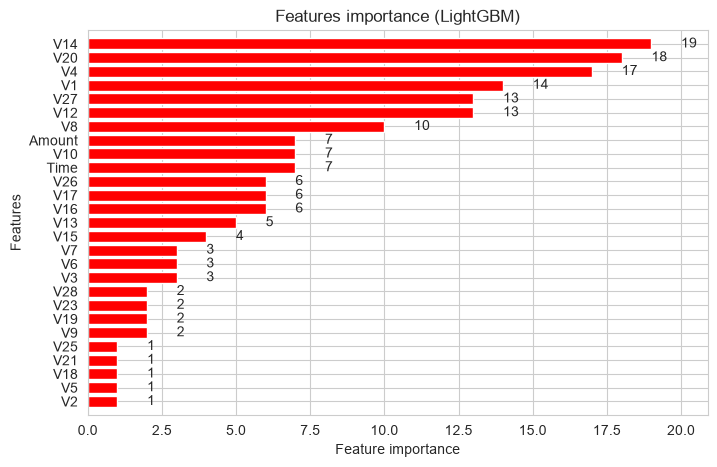

In [126]:
fig, (ax) = plt.subplots(ncols=1, figsize=(8,5))
lgb.plot_importance(model, height=0.8, title="Features importance (LightGBM)", ax=ax,color="red") 
plt.show()

In [127]:
# predict test data
preds = model.predict(test_df[predictors])

In [128]:
# Best validation AUC recorded during training
print('Best validation AUC: %.6f (iteration %d)'
      % (evals_results['valid']['auc'][model.best_iteration - 1], model.best_iteration))


Best validation AUC: 0.957864 (iteration 29)


In [129]:
proba_lgb_test = preds
proba_lgb_valid = model.predict(valid_df[predictors], num_iteration=model.best_iteration)
roc_auc_score(test_df[target].values, proba_lgb_test)


0.9473337202349549

**Training and validation using cross-validation**

Let's use now cross-validation. We will use cross-validation (KFolds) with 5 folds. Data is divided in 5 folds and, by rotation, we are training using 4 folds (n-1) and validate using the 5th (nth) fold.

Test set is calculated as an average of the predictions

In [130]:
import lightgbm as lgb

kf = KFold(n_splits=NUMBER_KFOLDS, random_state=RANDOM_STATE, shuffle=True)

# Create arrays and dataframes to store results
oof_preds = np.zeros(train_df.shape[0])
test_preds = np.zeros(test_df.shape[0])
feature_importance_df = pd.DataFrame()
n_fold = 0
for train_idx, valid_idx in kf.split(train_df):
    train_x, train_y = train_df[predictors].iloc[train_idx], train_df[target].iloc[train_idx]
    valid_x, valid_y = train_df[predictors].iloc[valid_idx], train_df[target].iloc[valid_idx]

    model = LGBMClassifier(
        n_jobs=-1,
        n_estimators=2000,
        learning_rate=0.01,
        num_leaves=80,
        colsample_bytree=0.98,
        subsample=0.78,
        reg_alpha=0.04,
        reg_lambda=0.073,
        subsample_for_bin=50,
        boosting_type='gbdt',
        is_unbalance=False,
        min_split_gain=0.025,
        min_child_weight=40,
        min_child_samples=510,
        objective='binary',
        metric='auc',
        verbose=-1)

    model.fit(train_x, train_y,
              eval_set=[(train_x, train_y), (valid_x, valid_y)],
              eval_metric='auc',
              callbacks=[
                  lgb.early_stopping(stopping_rounds=EARLY_STOP, verbose=False),
                  lgb.log_evaluation(period=VERBOSE_EVAL),
              ])

    oof_preds[valid_idx] = model.predict_proba(valid_x, num_iteration=model.best_iteration_)[:, 1]
    test_preds += model.predict_proba(test_df[predictors], num_iteration=model.best_iteration_)[:, 1] / kf.n_splits

    fold_importance_df = pd.DataFrame()
    fold_importance_df["feature"] = predictors
    fold_importance_df["importance"] = model.feature_importances_
    fold_importance_df["fold"] = n_fold + 1

    feature_importance_df = pd.concat([feature_importance_df, fold_importance_df], axis=0)
    print('Fold %2d AUC : %.6f' % (n_fold + 1, roc_auc_score(valid_y, oof_preds[valid_idx])))
    del model, train_x, train_y, valid_x, valid_y
    gc.collect()
    n_fold = n_fold + 1

train_auc_score = roc_auc_score(train_df[target], oof_preds)
print('Full AUC score %.6f' % train_auc_score)
# AUC on the test set, from the average of the 5 fold models
test_auc_score = roc_auc_score(test_df[target], test_preds)
print('Test AUC score %.6f' % test_auc_score)


c:\Users\Asus\anaconda3\envs\py311-ml\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


[50]	training's auc: 0.972313	valid_1's auc: 0.990201
[100]	training's auc: 0.97139	valid_1's auc: 0.992925
[150]	training's auc: 0.974237	valid_1's auc: 0.997586
[200]	training's auc: 0.974713	valid_1's auc: 0.997987
[250]	training's auc: 0.975847	valid_1's auc: 0.998143
Fold  1 AUC : 0.998184


c:\Users\Asus\anaconda3\envs\py311-ml\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


[50]	training's auc: 0.979082	valid_1's auc: 0.963933
Fold  2 AUC : 0.966302


c:\Users\Asus\anaconda3\envs\py311-ml\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


[50]	training's auc: 0.980517	valid_1's auc: 0.937209
[100]	training's auc: 0.981387	valid_1's auc: 0.938327
[150]	training's auc: 0.981624	valid_1's auc: 0.939771
[200]	training's auc: 0.981827	valid_1's auc: 0.942898
[250]	training's auc: 0.983151	valid_1's auc: 0.942886
Fold  3 AUC : 0.943196


c:\Users\Asus\anaconda3\envs\py311-ml\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


[50]	training's auc: 0.969943	valid_1's auc: 0.988765
[100]	training's auc: 0.97331	valid_1's auc: 0.992088
Fold  4 AUC : 0.993275


c:\Users\Asus\anaconda3\envs\py311-ml\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


[50]	training's auc: 0.962251	valid_1's auc: 0.976423
[100]	training's auc: 0.971749	valid_1's auc: 0.984237
[150]	training's auc: 0.972767	valid_1's auc: 0.983043
Fold  5 AUC : 0.984831
Full AUC score 0.970312
Test AUC score 0.967543


## Comparing models on one test set

Every model above was trained on the data as it is: no oversampling, no undersampling,
and no class weights except the LightGBM `scale_pos_weight` noted in its section.
This section measures what that choice cost.

The three label-based models were scored on the validation set and the two boosting
models on the test set, so their numbers are not directly comparable. Here every model
is scored on the test set with the same metric.

Accuracy is not reported: at a 0.16% fraud rate a model that never predicts fraud
already reaches 99.8%. PR-AUC and recall at a fixed threshold say more.


In [131]:
from sklearn.metrics import (average_precision_score, precision_recall_curve,
                             precision_score, recall_score, f1_score)

y_valid = valid_df[target].values
y_test = test_df[target].values

# Tuned on validation, applied to test, so the test set never informs the choice
def pick_threshold(y_true, proba):
    precision, recall, thresholds = precision_recall_curve(y_true, proba)
    f1 = 2 * precision * recall / (precision + recall + 1e-12)
    return thresholds[f1[:-1].argmax()]

proba_by_model = {
    'RandomForest': (proba_rf, proba_rf_test),
    'AdaBoost': (proba_ada, proba_ada_test),
    'CatBoost': (proba_cat, proba_cat_test),
    'XGBoost': (proba_xgb_valid, proba_xgb_test),
    'LightGBM': (proba_lgb_valid, proba_lgb_test),
}

rows = []
for name, (proba_valid, proba_test) in proba_by_model.items():
    threshold = pick_threshold(y_valid, proba_valid)
    predicted = (proba_test >= threshold).astype(int)
    rows.append({
        'Model': name,
        'Threshold': round(threshold, 4),
        'PR-AUC': round(average_precision_score(y_test, proba_test), 4),
        'ROC-AUC': round(roc_auc_score(y_test, proba_test), 4),
        'Recall': round(recall_score(y_test, predicted, zero_division=0), 3),
        'Precision': round(precision_score(y_test, predicted, zero_division=0), 3),
        'F1': round(f1_score(y_test, predicted, zero_division=0), 3),
    })

metrics_df = pd.DataFrame(rows).sort_values('PR-AUC', ascending=False)
metrics_df


,Model,Threshold,PR-AUC,ROC-AUC,Recall,Precision,F1
2,CatBoost,0.6529,0.8514,0.9783,0.75,0.962,0.843
0,RandomForest,0.5900,0.8413,0.9436,0.74,0.949,0.831
3,XGBoost,0.2991,0.8218,0.9719,0.77,0.865,0.815
1,AdaBoost,0.4580,0.7513,0.9714,0.76,0.731,0.745
4,LightGBM,0.9978,0.3480,0.9473,0.80,0.364,0.500


## Does class weighting help?

Class weighting is the alternative to resampling: it reweights the loss instead of
inventing rows with SMOTE or discarding them with undersampling. The LightGBM section
above sets `scale_pos_weight=150`, but the training set actually has 627 non-fraud
transactions per fraud, so 150 is a guess.

This compares no weighting, 150, and the true ratio on the same split, using PR-AUC
because it responds to weighting while ROC-AUC does not.


In [132]:
configs = {
    'no weighting': 1,
    'scale_pos_weight=150': 150,
    'scale_pos_weight=627': 627,
}

imbalance_rows = []
for label, weight in configs.items():
    config = {**params, 'scale_pos_weight': weight}
    train_set = lgb.Dataset(train_df[predictors].values,
                            label=train_df[target].values,
                            feature_name=predictors)
    valid_set = lgb.Dataset(valid_df[predictors].values,
                            label=valid_df[target].values,
                            feature_name=predictors)
    booster = lgb.train(
        config,
        train_set,
        num_boost_round=500,
        valid_sets=[valid_set],
        valid_names=['valid'],
        callbacks=[
            lgb.early_stopping(stopping_rounds=EARLY_STOP, verbose=False),
            lgb.log_evaluation(period=0),
        ],
    )
    proba = booster.predict(valid_df[predictors].values, num_iteration=booster.best_iteration)
    imbalance_rows.append({
        'Configuration': label,
        'Best iteration': booster.best_iteration,
        'PR-AUC': round(average_precision_score(y_valid, proba), 4),
        'ROC-AUC': round(roc_auc_score(y_valid, proba), 4),
    })

pd.DataFrame(imbalance_rows)


,Configuration,Best iteration,PR-AUC,ROC-AUC
0,no weighting,156,0.6890,0.9726
1,scale_pos_weight=150,29,0.2983,0.9579
2,scale_pos_weight=627,1,0.3598,0.9638


## Kesimpulan

Kami menyelidiki data dengan memeriksa ketidakseimbangan data (*data unbalancing*),
memvisualisasikan fitur-fitur, dan memahami hubungan antar fitur. Setelah itu, kami
menguji beberapa model prediktif. Data dibagi menjadi tiga bagian: *train set*
(182.276 baris), *validation set* (45.569 baris), dan *test set* (56.962 baris),
dengan hanya 0,16% transaksi penipuan di *train set*.

1. **RandomForestClassifier**: AUC **0,853** dari label kelas dan **0,910** dari
   probabilitas, pada *validation set* (100 estimator, kriteria GINI).
2. **AdaBoostClassifier**: AUC **0,814** dari label kelas dan **0,983** dari
   probabilitas, pada *validation set* (100 estimator, *learning rate* 0,8).
3. **CatBoostClassifier**: setelah 500 iterasi, AUC **0,858** dari label kelas dan
   **0,984** dari probabilitas, pada *validation set*.
4. **XGBoost**: model dilatih dengan *validation set* sebagai pemantau. AUC validasi
   terbaik **0,980** pada iterasi ke-77, dan *early stopping* menghentikan pelatihan
   pada iterasi ke-128. Skor AUC pada *test set* adalah **0,972**.
5. **LightGBM**: dievaluasi dengan dua metode.
   - Pembagian *train-validation*: AUC validasi **0,958** (iterasi ke-29) dan AUC
     *test set* **0,947**.
   - *Cross-validation* 5-fold: AUC *out-of-fold* **0,970**, dan AUC *test set* dari
     rata-rata 5 model adalah **0,968**. Skor per fold sangat bervariasi
     (0,943-0,998; simpangan baku 0,020) karena setiap fold hanya memuat 47-77
     transaksi penipuan.

## Ringkasan Hasil

| Model | AUC label kelas (validasi) | AUC probabilitas (validasi) | AUC (test) |
|---|---|---|---|
| RandomForestClassifier | 0,853 | 0,910 | - |
| AdaBoostClassifier | 0,814 | 0,983 | - |
| CatBoostClassifier | 0,858 | 0,984 | - |
| XGBoost | - | 0,980 (iterasi 77) | 0,972 |
| LightGBM (train-validation) | - | 0,958 (iterasi 29) | 0,947 |
| LightGBM (5-fold CV) | - | 0,970 (OOF) | 0,968 |

Pada kolom AUC (*test*), XGBoost tertinggi (**0,972**), diikuti LightGBM dengan
*cross-validation* (0,968) dan LightGBM *train-validation* (0,947). Kolom itu hanya
memuat tiga model dan hanya mengurutkan berdasarkan ROC-AUC; perbandingan setara
untuk kelima model ada di bagian berikutnya.

## Catatan mengenai perbandingan antar model

Tabel *Ringkasan Hasil* di atas **tidak sepenuhnya setara**, dan kesimpulan yang
terlalu jauh darinya perlu dihindari karena dua alasan.

Pertama, metrik yang dipakai berbeda. Untuk RandomForest, AdaBoost, dan CatBoost,
AUC dihitung dari label kelas hasil `predict`, sedangkan untuk XGBoost dan LightGBM
AUC dihitung dari probabilitas. AUC berbasis label kelas membuang informasi
*ranking*, sehingga angkanya secara sistematis lebih rendah dan tidak dapat
dibandingkan langsung. Ketika ketiga model pertama diukur dengan probabilitas pada
*validation set* yang sama, selisihnya hampir seluruhnya hilang: AdaBoost (0,983)
dan CatBoost (0,984) justru setara dengan XGBoost (0,980).

Kedua, set evaluasinya berbeda. RandomForest, AdaBoost, dan CatBoost dievaluasi pada
*validation set*, sementara XGBoost dan LightGBM dilaporkan pada *test set*. Karena
itu tidak ada dasar untuk mengurutkan performa keenam model dari tabel di atas.

## Perbandingan pada satu test set

Bagian *Comparing models on one test set* mengukur kelima model pada *test set* yang
sama, dengan *threshold* yang ditentukan dari *validation set* sehingga *test set*
tidak pernah memengaruhi pemilihan *threshold*. Model dilatih pada data apa adanya:
tidak ada SMOTE, tidak ada *undersampling*, dan tidak ada pembobotan kelas kecuali
`scale_pos_weight` pada LightGBM.

| Model | Threshold | PR-AUC | ROC-AUC | Recall | Precision | F1 |
|---|---|---|---|---|---|---|
| CatBoost | 0,653 | **0,851** | 0,978 | 0,75 | 0,962 | **0,843** |
| RandomForest | 0,590 | 0,841 | 0,944 | 0,74 | 0,949 | 0,831 |
| XGBoost | 0,299 | 0,822 | 0,972 | 0,77 | 0,865 | 0,815 |
| AdaBoost | 0,458 | 0,751 | 0,971 | 0,76 | 0,731 | 0,745 |
| LightGBM | 0,998 | 0,348 | 0,947 | 0,80 | 0,364 | 0,500 |

Model dengan PR-AUC tertinggi adalah **CatBoost** (0,851), diikuti **RandomForest**
(0,841) dan **XGBoost** (0,822). **AdaBoost** berada di bawahnya (0,751), dan
**LightGBM** tertinggal jauh (0,348).

Dua hal menarik dari tabel ini. Pertama, urutan PR-AUC **tidak sama** dengan urutan
ROC-AUC: RandomForest memiliki ROC-AUC paling rendah (0,944) tetapi PR-AUC kedua
tertinggi, sementara XGBoost yang ROC-AUC-nya 0,972 hanya berada di posisi ketiga.
ROC-AUC memberi bobot sama pada seluruh rentang *false positive*, sedangkan PR-AUC
hanya peduli pada peringkat teratas daftar — bagian yang benar-benar dipakai untuk
menyaring transaksi. Untuk kasus *fraud*, PR-AUC lebih dekat ke keputusan nyata.

Kedua, LightGBM menjadi contoh kegagalan pembobotan kelas. Karena dilatih dengan
`scale_pos_weight=150` dan berhenti di iterasi ke-29, probabilitasnya tidak
terkalibrasi, sehingga *threshold* hasil *tuning* melonjak ke 0,998. Pada *threshold*
itu recall masih 0,80 tetapi precision hanya 0,364, artinya dua dari tiga transaksi
yang ditandai penipuan sebenarnya sah.

## Apakah pembobotan kelas membantu?

Eksperimen *Does class weighting help?* membandingkan tiga konfigurasi LightGBM pada
pembagian data yang sama. Pembobotan kelas adalah alternatif dari *resampling*: ia
membobot ulang *loss* tanpa membangkitkan baris sintetis (SMOTE) atau membuang baris
(*undersampling*).

| Konfigurasi | Best iteration | PR-AUC | ROC-AUC |
|---|---|---|---|
| tanpa pembobotan | 156 | **0,689** | 0,973 |
| `scale_pos_weight=150` | 29 | 0,298 | 0,958 |
| `scale_pos_weight=627` | 1 | 0,360 | 0,964 |

Pembobotan kelas **tidak membantu**, bahkan merugikan. Tanpa pembobotan, LightGBM
mencapai PR-AUC 0,689 dan ROC-AUC 0,973 dengan 156 iterasi. Setelah diberi bobot
150, PR-AUC jatuh ke 0,298 dan pelatihan berhenti di iterasi ke-29. Dengan bobot
627 — rasio sebenarnya antara transaksi sah dan penipuan di *train set* — PR-AUC
0,360 dan *early stopping* menghentikan pelatihan setelah **satu** iterasi, sehingga
model praktis tidak belajar sama sekali.

Mekanismenya: `scale_pos_weight` yang besar membuat *gradient* kelas positif
mendominasi, sehingga *loss* validasi memburuk sejak iterasi awal dan *early
stopping* langsung memicu berhenti. Bobot yang lebih besar bukan berarti deteksi yang
lebih baik.

Angka PR-AUC LightGBM di tabel ini (0,689) berbeda dari tabel sebelumnya (0,348)
karena set evaluasinya berbeda — yang ini pada *validation set*, yang sebelumnya pada
*test set* dengan *threshold* dari model berbobot. Keduanya konsisten menunjukkan
bahwa pembobotan menurunkan kualitas peringkat.

Kesimpulannya, penanganan *imbalance* yang tepat untuk data ini bukan *resampling*
maupun pembobotan kelas, melainkan pemilihan *threshold* dan pelaporan PR-AUC seperti
pada bagian sebelumnya. Ini juga alasan notebook ini tidak memakai SMOTE: dengan
hanya 290 transaksi penipuan di *train set*, SMOTE akan membangkitkan ratusan ribu
baris sintetis dari 290 titik asli dan membuat metrik validasi tidak lagi
mencerminkan data nyata.
